# 05 — Run one pipeline batch step by step
Run notebook 01 first. The functions below are defined in notebook cells. They are synchronized to the Python modules used by Airflow. Ingest, clean, train and finish write to the application database and MLflow. Do not run this notebook and the DAG at the same time.


In [1]:
%matplotlib inline

In [2]:
import sys
from pathlib import Path
project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from io import BytesIO
from sqlalchemy import text


## Functions: settings
This is the editable source. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [3]:
import os
from urllib.parse import quote_plus


In [4]:
def database_url():
    user = quote_plus(os.environ['DIABETES_DB_USER'])
    pwd = quote_plus(os.environ['DIABETES_DB_PASSWORD'])
    host = os.getenv('DIABETES_DB_HOST', 'diabetes-postgres.mlops-project.svc.cluster.local')
    db = quote_plus(os.getenv('DIABETES_DB_NAME', 'diabetes'))
    return f'postgresql+psycopg2://{user}:{pwd}@{host}:5432/{db}'


In [5]:
def s3_client():
    import boto3
    return boto3.client('s3', endpoint_url=os.getenv('S3_ENDPOINT_URL','http://minio.mlops-project.svc.cluster.local:9000'), region_name='us-east-1', aws_access_key_id=os.environ['AWS_ACCESS_KEY_ID'], aws_secret_access_key=os.environ['AWS_SECRET_ACCESS_KEY'])


## Functions: preprocessing
This is a copy; edit the source in 03_preprocessing.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [6]:
import hashlib
import numpy as np
import pandas as pd
NUMERIC_FEATURES = (
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses',
)
SPLIT_STRATEGY = 'patient_nbr_sha256_70_15_15'


In [7]:
def split_for_patient(patient_id):
    value = int(hashlib.sha256(str(int(patient_id)).encode()).hexdigest()[:12], 16) % 10000
    return 'train' if value < 7000 else ('validation' if value < 8500 else 'test')


In [8]:
def normalize_features(features):
    """Keep categorical columns categorical, even when an entire batch is missing."""
    result = features.copy()
    result = result.mask(result.eq('?'))
    for column in result:
        if column in NUMERIC_FEATURES:
            result[column] = pd.to_numeric(result[column], errors='coerce').astype('float64')
        else:
            result[column] = result[column].map(
                lambda value: str(value) if pd.notna(value) else np.nan
            ).astype(object)
    return result


In [9]:
def prepare_records(df):
    required = {'encounter_id', 'patient_nbr', 'readmitted'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing columns: {required - set(df.columns)}')
    df = df.copy().reset_index(drop=True)
    df = df.mask(df.eq('?'))
    if df[['encounter_id', 'patient_nbr', 'readmitted']].isna().any().any():
        raise ValueError('Encounter ID, patient ID and readmission label are required')
    unexpected = set(df['readmitted'].unique()) - {'NO', '>30', '<30'}
    if unexpected:
        raise ValueError(f'Unexpected readmission labels: {unexpected}')
    df['target'] = df['readmitted'].eq('<30').astype('int8')
    df['split'] = df['patient_nbr'].map(split_for_patient)
    excluded = {'encounter_id', 'patient_nbr', 'readmitted', 'target', 'split', 'discharge_disposition_id'}
    features = normalize_features(df.drop(columns=[c for c in excluded if c in df.columns]))
    return df[['encounter_id', 'patient_nbr', 'target', 'split']], features


## Functions: training
This is a copy; edit the source in 04_modeling.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [10]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix


In [11]:
def make_pipeline(frame,kind='logistic'):
    numbers=frame.select_dtypes(include='number').columns.tolist()
    categories=[c for c in frame.columns if c not in numbers]
    steps=[]
    if numbers: steps.append(('num',Pipeline([('fill',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),numbers))
    if categories: steps.append(('cat',Pipeline([('fill',SimpleImputer(strategy='constant',fill_value='missing',keep_empty_features=True)),('encode',OneHotEncoder(handle_unknown='ignore'))]),categories))
    prep=ColumnTransformer(steps)
    if kind not in ('logistic', 'forest'): raise ValueError(f'Unknown model: {kind}')
    model= LogisticRegression(max_iter=500,class_weight='balanced',random_state=42) if kind=='logistic' else RandomForestClassifier(n_estimators=100,min_samples_leaf=5,random_state=42,n_jobs=2,class_weight='balanced_subsample')
    return Pipeline([('preprocess',prep),('model',model)])


In [12]:
def score_predictions(y, predicted, probabilities):
    """Report counts and classification scores; undefined AUCs remain null."""
    y = np.asarray(y, dtype=int)
    predicted = np.asarray(predicted, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    if len(y) == 0:
        return None
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    result = {
        'n': int(len(y)), 'positive': int((y == 1).sum()), 'negative': int((y == 0).sum()),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'accuracy': float(accuracy_score(y, predicted)),
        'precision': float(precision_score(y, predicted, zero_division=0)),
        'recall': float(recall_score(y, predicted, zero_division=0)),
        'f1': float(f1_score(y, predicted, zero_division=0)),
        'roc_auc': None, 'pr_auc': None,
    }
    if len(np.unique(y)) == 2:
        result['roc_auc'] = float(roc_auc_score(y, probabilities))
        # This is average precision, not trapezoidal PR-curve area.
        result['pr_auc'] = float(average_precision_score(y, probabilities))
    return result


def metrics(model, X, y):
    if len(y) == 0:
        return None
    positive_column = list(model.classes_).index(1)
    return score_predictions(y, model.predict(X), model.predict_proba(X)[:, positive_column])


## Functions: pipeline
This is the editable source. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [13]:
import io, json, os, pathlib
import pandas as pd
from sqlalchemy import create_engine, text
BUCKET='diabetes-source'
MODEL_SCHEMA_VERSION='patient_split_categorical_v2'


In [14]:
def engine(): return create_engine(database_url(),pool_pre_ping=True)


In [15]:
def init_schema(sql_path=None):
    if sql_path is None:
        sql_path = pathlib.Path(__file__).resolve().parents[2] / 'sql' / '01_schema.sql'
    else:
        sql_path = pathlib.Path(sql_path)
    # The SQL file is mounted under /opt/airflow/src/../sql for Airflow.
    if not sql_path.exists(): sql_path=pathlib.Path('/opt/airflow/sql/01_schema.sql')
    with engine().begin() as conn:
        for stmt in sql_path.read_text().split(';'):
            if stmt.strip(): conn.execute(text(stmt))


In [16]:
def next_batch():
    s3=s3_client()
    resp=s3.list_objects_v2(Bucket=BUCKET,Prefix='batches/')
    keys=sorted(x['Key'] for x in resp.get('Contents',[]) if x['Key'].endswith('.csv'))
    with engine().connect() as conn:
        done={r[0] for r in conn.execute(text("SELECT batch_id FROM audit.ingestion_batches WHERE status='completed'"))}
    for key in keys:
        batch=key.rsplit('/',1)[-1].removesuffix('.csv')
        if batch not in done: return {'key':key,'batch_id':batch}
    return None


In [17]:
def ensure_registry_compatible():
    """Reject legacy model versions before ingesting a new batch."""
    import mlflow
    from mlflow.tracking import MlflowClient
    mlflow.set_tracking_uri(os.getenv('MLFLOW_TRACKING_URI', 'http://mlflow-mlflow.mlops-project.svc.cluster.local:5000'))
    client = MlflowClient()
    required = {'feature_schema', 'cohort', 'algorithm', 'created_batch', 'training_batches'}
    incompatible = []
    for version in client.search_model_versions("name='diabetes-readmission'"):
        if required.issubset(version.tags) and version.tags['feature_schema'] == MODEL_SCHEMA_VERSION:
            continue
        run = client.get_run(version.run_id) if version.run_id else None
        params = run.data.params if run else {}
        if params.get('feature_schema') == MODEL_SCHEMA_VERSION and all(params.get(k) for k in ('cohort', 'algorithm', 'batch', 'training_batches')):
            continue  # The training step can recover tags after an interrupted registration.
        incompatible.append(str(version.version))
    if incompatible:
        raise ValueError('Existing model versions use the previous feature schema: '
                         + ', '.join(incompatible) + '. Reset the project before ingesting the next batch.')


In [18]:
def ingest(item):
    if not item: return None
    s3=s3_client()
    body=s3.get_object(Bucket=BUCKET,Key=item['key'])['Body'].read()
    # Keep raw CSV field values as strings; do not replace missing-value markers.
    frame=pd.read_csv(io.BytesIO(body),dtype=str,keep_default_na=False)
    if frame.empty or len(frame)>15000: raise ValueError('Batch must contain 1 to 15,000 rows')
    required={'encounter_id','patient_nbr','readmitted'}
    if not required.issubset(frame.columns): raise ValueError(f'Missing columns: {required-set(frame.columns)}')
    for column in ('encounter_id','patient_nbr'):
        if not frame[column].str.fullmatch(r'\d+').all(): raise ValueError(f'Invalid {column}')
    if frame.encounter_id.map(int).duplicated().any(): raise ValueError('Duplicate encounter within source batch')
    # One transaction prevents partial batches from becoming completed.
    with engine().begin() as conn:
        status=conn.execute(text('SELECT status FROM audit.ingestion_batches WHERE batch_id=:b FOR UPDATE'),{'b':item['batch_id']}).scalar()
        if status == 'completed':
            raise ValueError(f"Batch already completed: {item['batch_id']}; discover the next batch instead")
        conn.execute(text("INSERT INTO audit.ingestion_batches (batch_id,source_key,status) VALUES (:b,:s,'processing') ON CONFLICT (batch_id) DO UPDATE SET status='processing',started_at=now(),completed_at=NULL"),{'b':item['batch_id'],'s':item['key']})
        conn.execute(text('DELETE FROM clean.encounters WHERE batch_id=:b'),{'b':item['batch_id']})
        conn.execute(text('DELETE FROM raw.encounters WHERE batch_id=:b'),{'b':item['batch_id']})
        rows=[{'e':int(r['encounter_id']),'p':int(r['patient_nbr']),'b':item['batch_id'],'s':item['key'],'o':json.dumps(r,default=str)} for r in frame.to_dict(orient='records')]
        # Protect the unique encounter key from duplicate inserts across batches.
        collisions=conn.execute(text('SELECT count(*) FROM raw.encounters WHERE encounter_id = ANY(:ids)'),{'ids':[r['e'] for r in rows]}).scalar()
        if collisions: raise ValueError(f'{collisions} encounter IDs already ingested from another batch')
        conn.execute(text('INSERT INTO raw.encounters(encounter_id,patient_nbr,batch_id,source_key,original) VALUES (:e,:p,:b,:s,CAST(:o AS jsonb))'),rows)
        conn.execute(text("UPDATE audit.ingestion_batches SET row_count=:n WHERE batch_id=:b"),{'n':len(rows),'b':item['batch_id']})
    return item


In [19]:
def clean_batch(item):
    if not item: return None
    with engine().begin() as conn:
        rs=conn.execute(text('SELECT original FROM raw.encounters WHERE batch_id=:b ORDER BY encounter_id'),{'b':item['batch_id']}).fetchall()
        df=pd.DataFrame([r[0] for r in rs])
        if df.empty: raise ValueError('Empty source batch')
        meta, features=prepare_records(df)
        items=[]
        for i,row in meta.iterrows():
            f={k:(None if pd.isna(v) else v) for k,v in features.loc[i].items()}
            items.append({'e':int(row.encounter_id),'p':int(row.patient_nbr),'b':item['batch_id'],'sp':row.split,'y':int(row.target),'f':json.dumps(f,default=str)})
        conn.execute(text('INSERT INTO clean.encounters(encounter_id,patient_nbr,batch_id,split,target,features) VALUES (:e,:p,:b,:sp,:y,CAST(:f AS jsonb)) ON CONFLICT(encounter_id) DO UPDATE SET features=EXCLUDED.features,split=EXCLUDED.split,target=EXCLUDED.target,processed_at=now()'),items)
    return item


In [20]:
def load_clean():
    with engine().connect() as conn:
        rows=conn.execute(text('SELECT encounter_id,batch_id,split,target,features FROM clean.encounters ORDER BY encounter_id')).mappings().all()
    if not rows: raise ValueError('No cleaned training data')
    X=normalize_features(pd.DataFrame([r['features'] for r in rows]))
    return rows,X


In [21]:
def evaluate_model(model, X, table, metadata):
    """Evaluate one fitted model on each batch/split and on pooled splits."""
    predictions = model.predict(X)
    positive_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(X)[:, positive_column]
    y = table['target'].to_numpy()
    batch_ids = sorted(table['batch_id'].unique())
    trained = set(metadata['training_batches'])
    results = []
    for split in ('train', 'validation', 'test'):
        for batch in batch_ids + ['all']:
            mask = table['split'].eq(split)
            if batch != 'all':
                mask &= table['batch_id'].eq(batch)
            mask = mask.to_numpy()
            if not mask.any():
                continue
            seen = None
            if split == 'train':
                seen = ('yes' if batch in trained else 'no') if batch != 'all' else (
                    'yes' if set(batch_ids).issubset(trained) else 'mixed')
            scores = score_predictions(y[mask], predictions[mask], probabilities[mask])
            results.append({**metadata, 'training_batches': ','.join(metadata['training_batches']),
                            'split': split, 'evaluation_batch': batch,
                            'training_rows_seen': seen, **scores})
    return results


In [22]:
def train_and_compare(item):
    """Train candidates, compare all compatible versions and promote by validation ROC-AUC."""
    if not item:
        return {'message': 'No pending batch; skipped training.'}
    import gc
    import mlflow
    import mlflow.sklearn
    from mlflow.exceptions import MlflowException
    from mlflow.tracking import MlflowClient
    from mlflow.models import infer_signature
    from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
    import matplotlib.pyplot as plt

    registered_name = 'diabetes-readmission'
    schema_version = MODEL_SCHEMA_VERSION
    mlflow.set_tracking_uri(os.getenv('MLFLOW_TRACKING_URI', 'http://mlflow-mlflow.mlops-project.svc.cluster.local:5000'))
    mlflow.set_experiment('diabetes-pipeline')
    client = MlflowClient()
    versions = list(client.search_model_versions(f"name='{registered_name}'"))
    required_tags = {'feature_schema', 'cohort', 'algorithm', 'created_batch', 'training_batches'}
    incompatible = []
    for version in versions:
        if required_tags.issubset(version.tags) and version.tags['feature_schema'] == schema_version:
            continue
        # A retry may find a version registered just before a tag write failed.
        run = client.get_run(version.run_id) if version.run_id else None
        params = run.data.params if run else {}
        if params.get('feature_schema') != schema_version or not all(params.get(k) for k in ('cohort', 'algorithm', 'batch', 'training_batches')):
            incompatible.append(str(version.version))
            continue
        recovered = {'feature_schema': schema_version, 'cohort': params['cohort'],
                     'algorithm': params['algorithm'], 'created_batch': params['batch'],
                     'training_batches': json.dumps(params['training_batches'].split(','))}
        for tag, value in recovered.items():
            client.set_model_version_tag(registered_name, str(version.version), tag, value)
    if incompatible:
        raise ValueError('Existing model versions use the previous feature schema: '
                         + ', '.join(incompatible) + '. Reset the project before the clean run.')
    versions = list(client.search_model_versions(f"name='{registered_name}'"))

    rows, X = load_clean()
    table = pd.DataFrame([{'batch_id': r['batch_id'], 'split': r['split'], 'target': r['target']} for r in rows])
    y = table['target']
    train = table['split'].eq('train')
    validation = table['split'].eq('validation')
    latest = table['batch_id'].eq(item['batch_id'])
    if y[train].nunique() < 2 or y[validation].nunique() < 2:
        raise ValueError('Accumulated train and validation must each contain both target classes for ROC-AUC.')

    cohorts = [('cumulative', train)]
    if not (train & latest).equals(train):
        cohorts.insert(0, ('latest_batch', train & latest))
    existing = {(v.tags.get('created_batch'), v.tags.get('cohort'), v.tags.get('algorithm')): v
                for v in versions}
    requirements = ['mlflow==3.17.2', 'scikit-learn==1.7.1', 'numpy==2.2.6',
                    'pandas==2.3.1', 'skops==0.16.0']

    for cohort, mask in cohorts:
        if mask.sum() < 30 or y[mask].nunique() < 2:
            raise ValueError(f'Insufficient training rows or target classes for {cohort}.')
        training_batches = sorted(table.loc[mask, 'batch_id'].unique())
        for algorithm in ('logistic', 'forest'):
            key = (item['batch_id'], cohort, algorithm)
            if key in existing:
                print(f'Reusing registered version {existing[key].version} for {key}')
                continue
            print(f'Training {cohort} / {algorithm} on {int(mask.sum())} rows')
            model = make_pipeline(X.loc[mask], algorithm)
            model.fit(X.loc[mask], y.loc[mask])
            metadata = {'version': 'pending', 'algorithm': algorithm, 'cohort': cohort,
                        'created_batch': item['batch_id'], 'training_batches': training_batches}
            evaluation = evaluate_model(model, X, table, metadata)
            in_sample = metrics(model, X.loc[mask], y.loc[mask])
            with mlflow.start_run(run_name=f"{item['batch_id']}-{cohort}-{algorithm}"):
                mlflow.log_params({'cohort': cohort, 'algorithm': algorithm,
                                   'batch': item['batch_id'], 'train_rows': int(mask.sum()),
                                   'training_batches': ','.join(training_batches),
                                   'split_strategy': SPLIT_STRATEGY,
                                   'selection_metric': 'accumulated_validation_roc_auc',
                                   'feature_schema': schema_version})
                model_params = {f'model_{k}': str(v) for k, v in model.named_steps['model'].get_params(deep=False).items()}
                mlflow.log_params(model_params)
                mlflow.log_metrics({f'train_in_sample_{k}': v for k, v in in_sample.items() if v is not None})
                for split in ('validation', 'test'):
                    aggregate = next((r for r in evaluation if r['split'] == split and r['evaluation_batch'] == 'all'), None)
                    if aggregate:
                        mlflow.log_metrics({f'{split}_{k}': aggregate[k] for k in (
                            'n', 'positive', 'negative', 'tn', 'fp', 'fn', 'tp',
                            'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc')
                            if aggregate[k] is not None})
                fig, axes = plt.subplots(1, 3, figsize=(15, 4))
                ConfusionMatrixDisplay.from_estimator(model, X.loc[validation], y.loc[validation], ax=axes[0])
                RocCurveDisplay.from_estimator(model, X.loc[validation], y.loc[validation], ax=axes[1])
                PrecisionRecallDisplay.from_estimator(model, X.loc[validation], y.loc[validation], ax=axes[2])
                fig.tight_layout()
                mlflow.log_figure(fig, 'evaluation/validation_plots.png')
                plt.close(fig)
                signature = infer_signature(X.loc[mask].head(10), model.predict(X.loc[mask].head(10)))
                info = mlflow.sklearn.log_model(model, name='model', signature=signature,
                    registered_model_name=registered_name, pip_requirements=requirements,
                    skops_trusted_types=['numpy.dtype', 'sklearn.tree._tree.Tree'])
                if info.registered_model_version is None:
                    raise RuntimeError('MLflow did not return a registered model version.')
                for row in evaluation:
                    row['version'] = str(info.registered_model_version)
                mlflow.log_dict({'rows': evaluation}, 'evaluation/metrics_by_batch.json')
                for tag, value in {'feature_schema': schema_version, 'cohort': cohort,
                                   'algorithm': algorithm, 'created_batch': item['batch_id'],
                                   'training_batches': json.dumps(training_batches)}.items():
                    client.set_model_version_tag(registered_name, str(info.registered_model_version), tag, value)
                print(f'Registered {registered_name} version {info.registered_model_version}')
            del model
            gc.collect()

    try:
        champion_before = str(client.get_model_version_by_alias(registered_name, 'champion').version)
    except MlflowException as exc:
        if exc.error_code != 'RESOURCE_DOES_NOT_EXIST' and 'registered model alias champion not found' not in str(exc).lower():
            raise
        champion_before = None

    all_rows = []
    for version in client.search_model_versions(f"name='{registered_name}'"):
        tags = version.tags
        if tags.get('feature_schema') != schema_version:
            raise ValueError(f'Incompatible model version {version.version}; reset before comparing.')
        metadata = {'version': str(version.version), 'algorithm': tags['algorithm'],
                    'cohort': tags['cohort'], 'created_batch': tags['created_batch'],
                    'training_batches': json.loads(tags['training_batches'])}
        print(f'Evaluating version {version.version} on all available splits')
        model = mlflow.sklearn.load_model(f'models:/{registered_name}/{version.version}')
        all_rows.extend(evaluate_model(model, X, table, metadata))
        del model
        gc.collect()

    scores = pd.DataFrame(all_rows)
    ranking = scores[(scores['split'] == 'validation') & (scores['evaluation_batch'] == 'all') & scores['roc_auc'].notna()]
    if ranking.empty:
        raise ValueError('No model has a defined ROC-AUC on accumulated validation.')
    best_score = float(ranking['roc_auc'].max())
    tied = ranking[ranking['roc_auc'] == best_score]
    if champion_before is not None and champion_before in tied['version'].tolist():
        champion_after = champion_before
    else:
        champion_after = str(tied.sort_values('version', key=lambda col: col.astype(int)).iloc[0]['version'])

    with mlflow.start_run(run_name=f"{item['batch_id']}-comparison") as run:
        mlflow.log_params({'batch': item['batch_id'], 'selection_metric': 'accumulated_validation_roc_auc',
                           'selection_split': 'validation', 'split_strategy': SPLIT_STRATEGY,
                           'champion_before': champion_before or 'none', 'champion_after': champion_after})
        mlflow.log_metric('selected_validation_roc_auc', best_score)
        mlflow.log_dict({'rows': all_rows}, 'evaluation/metrics.json')
        mlflow.log_text(scores.to_csv(index=False), 'evaluation/metrics.csv')
        by_batch = scores[(scores['split'] == 'validation') & (scores['evaluation_batch'] != 'all')]
        if not by_batch.empty and by_batch['roc_auc'].notna().any():
            plot_data = by_batch.pivot(index='evaluation_batch', columns='version', values='roc_auc')
            ax = plot_data.plot.bar(figsize=(10, 4), ylim=(0, 1), rot=0)
            ax.set_ylabel('Validation ROC-AUC'); ax.set_title('Model versions by batch')
            ax.figure.tight_layout()
            mlflow.log_figure(ax.figure, 'evaluation/validation_roc_auc_by_batch.png')
            plt.close(ax.figure)
        comparison_run_id = run.info.run_id

    if champion_after != champion_before:
        client.set_registered_model_alias(registered_name, 'champion', champion_after)
    print(f'Champion version {champion_after}; accumulated validation ROC-AUC={best_score:.4f}')
    return {'batch_id': item['batch_id'], 'champion_before': champion_before,
            'champion_after': champion_after, 'selection_metric': 'validation_roc_auc',
            'validation_roc_auc': best_score, 'comparison_run_id': comparison_run_id,
            'models_compared': int(ranking.shape[0])}


## Send tested functions to Airflow
The DAG uses the Python modules in `src/diabetes`. If you change functions in the notebooks, update the corresponding Python modules manually so Airflow uses the same code.

## 1. Find the next batch
`init_schema` creates empty tables if necessary. A batch is completed only after the final step succeeds; an interrupted batch can be retried.

In [23]:
init_schema(project / 'sql' / '01_schema.sql')
item = next_batch()
training_done = False
print('Next pending batch:', item if item else 'No pending batches')

Next pending batch: {'key': 'batches/batch_0001.csv', 'batch_id': 'batch_0001'}


## 2. Preview the raw data and proposed splits
These cells read the source object without ingesting it.

15,000 encounters and 11,886 patients


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


target,0,1,All
split,,,
test,2115,274,2389
train,9304,1146,10450
validation,1928,233,2161
All,13347,1653,15000


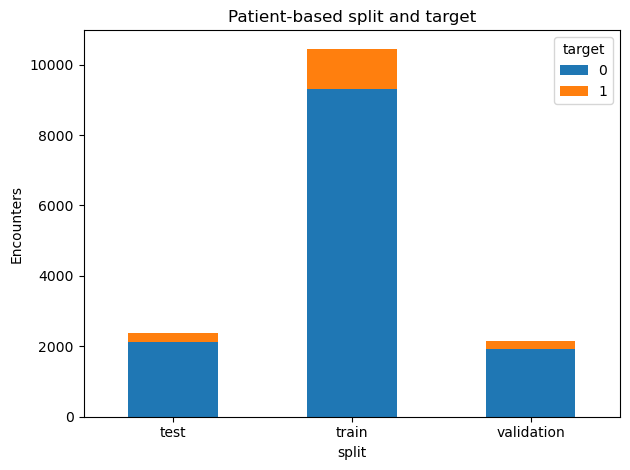

In [24]:
if item:
    body = s3_client().get_object(Bucket='diabetes-source', Key=item['key'])['Body'].read()
    batch = pd.read_csv(BytesIO(body), dtype=str, keep_default_na=False)
    preview, _ = prepare_records(batch)
    print(f'{len(batch):,} encounters and {batch.patient_nbr.nunique():,} patients')
    display(batch.head(3))
    display(pd.crosstab(preview['split'], preview['target'], margins=True))
    pd.crosstab(preview['split'], preview['target']).plot.bar(stacked=True, rot=0, title='Patient-based split and target')
    plt.ylabel('Encounters'); plt.tight_layout(); plt.show()

## 3. Ingest RAW and write CLEAN
Running these cells writes the selected batch to PostgreSQL. RAW preserves the source fields; CLEAN stores prepared features, the binary target and the patient split.

In [25]:
if item:
    ensure_registry_compatible()
    ingest(item)
    print('RAW ingested:', item['batch_id'])

RAW ingested: batch_0001


In [26]:
if item:
    clean_batch(item)
    with engine().connect() as connection:
        counts = pd.read_sql_query(text("SELECT split, target, count(*) AS encounters FROM clean.encounters WHERE batch_id=:batch GROUP BY split,target ORDER BY split,target"), connection, params={'batch': item['batch_id']})
    display(counts)

,split,target,encounters
0,test,0,2115
1,test,1,274
2,train,0,9304
3,train,1,1146
4,validation,0,1928
5,validation,1,233


## 4. Train, compare and complete
Save all candidates. Evaluate every compatible registered version on train, validation and test, per batch and pooled. Only pooled validation ROC-AUC selects the champion. The reported test values are monitoring results, not a separate final holdout.


In [27]:
if item:
    outcome = train_and_compare(item)
    training_done = True
    display(outcome)

2026/11/02 23:52:13 INFO mlflow.tracking.fluent: Experiment with name 'diabetes-pipeline' does not exist. Creating a new experiment.


Training cumulative / logistic on 10450 rows


Successfully registered model 'diabetes-readmission'.
2026/11/02 23:52:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: diabetes-readmission, version 1
Created version '1' of model 'diabetes-readmission'.


Registered diabetes-readmission version 1
🏃 View run batch_0001-cumulative-logistic at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2/runs/19c3e0a3c0794d94870c0c62cd877b18
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2
Training cumulative / forest on 10450 rows


Registered model 'diabetes-readmission' already exists. Creating a new version of this model...
2026/11/02 23:52:37 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: diabetes-readmission, version 2
Created version '2' of model 'diabetes-readmission'.


Registered diabetes-readmission version 2
🏃 View run batch_0001-cumulative-forest at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2/runs/451fa123fafc462c9ac81083973ebb4b
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2
Evaluating version 2 on all available splits


... (2 outputs left out)

{'batch_id': 'batch_0001',
 'champion_before': None,
 'champion_after': '2',
 'selection_metric': 'validation_roc_auc',
 'validation_roc_auc': 0.6460273716453263,
 'comparison_run_id': 'ea68d85f56384cd8812225acfdf7480a',
 'models_compared': 2}

Evaluating version 1 on all available splits


🏃 View run batch_0001-comparison at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2/runs/d008b63ffa124f18bf274bf7cc6938c2
🧪 View experiment at: http://mlflow-mlflow.mlops-project.svc.cluster.local:5000/#/experiments/2
Champion version 2; accumulated validation ROC-AUC=0.6460


{'batch_id': 'batch_0001',
 'champion_before': None,
 'champion_after': '2',
 'selection_metric': 'validation_roc_auc',
 'validation_roc_auc': 0.6460273716453263,
 'comparison_run_id': 'd008b63ffa124f18bf274bf7cc6938c2',
 'models_compared': 2}

In [28]:
def finish_batch(item):
    """Only mark the batch complete after ingestion, cleaning and training succeed."""
    if not item: return None
    with engine().begin() as conn:
        result=conn.execute(text("UPDATE audit.ingestion_batches SET status='completed',completed_at=now() WHERE batch_id=:b AND status='processing'"),{'b':item['batch_id']})
        if result.rowcount != 1:
            status=conn.execute(text('SELECT status FROM audit.ingestion_batches WHERE batch_id=:b'),{'b':item['batch_id']}).scalar()
            if status != 'completed': raise ValueError(f"Batch is not processing: {item['batch_id']}")
    return item


### Compare all model versions
The table includes each batch and `all` pooled rows. `training_rows_seen` indicates whether training-split rows were used to train that model; `pr_auc` is average precision.


,version,algorithm,cohort,created_batch,training_batches,split,evaluation_batch,training_rows_seen,n,positive,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
11,1,logistic,cumulative,batch_0001,batch_0001,test,all,NaN,2389,274,0.642528,0.146341,0.437956,0.219378,0.583246,0.152966,1415,700,154,120
10,1,logistic,cumulative,batch_0001,batch_0001,test,batch_0001,NaN,2389,274,0.642528,0.146341,0.437956,0.219378,0.583246,0.152966,1415,700,154,120
7,1,logistic,cumulative,batch_0001,batch_0001,train,all,yes,10450,1146,0.718278,0.244747,0.752182,0.369323,0.807402,0.306294,6644,2660,284,862
6,1,logistic,cumulative,batch_0001,batch_0001,train,batch_0001,yes,10450,1146,0.718278,0.244747,0.752182,0.369323,0.807402,0.306294,6644,2660,284,862
9,1,logistic,cumulative,batch_0001,batch_0001,validation,all,NaN,2161,233,0.649236,0.147651,0.472103,0.224949,0.609731,0.162776,1293,635,123,110
8,1,logistic,cumulative,batch_0001,batch_0001,validation,batch_0001,NaN,2161,233,0.649236,0.147651,0.472103,0.224949,0.609731,0.162776,1293,635,123,110
5,2,forest,cumulative,batch_0001,batch_0001,test,all,NaN,2389,274,0.789033,0.209596,0.302920,0.247761,0.639097,0.182310,1802,313,191,83
4,2,forest,cumulative,batch_0001,batch_0001,test,batch_0001,NaN,2389,274,0.789033,0.209596,0.302920,0.247761,0.639097,0.182310,1802,313,191,83
1,2,forest,cumulative,batch_0001,batch_0001,train,all,yes,10450,1146,0.866890,0.436098,0.729494,0.545870,0.907225,0.596239,8223,1081,310,836
0,2,forest,cumulative,batch_0001,batch_0001,train,batch_0001,yes,10450,1146,0.866890,0.436098,0.729494,0.545870,0.907225,0.596239,8223,1081,310,836


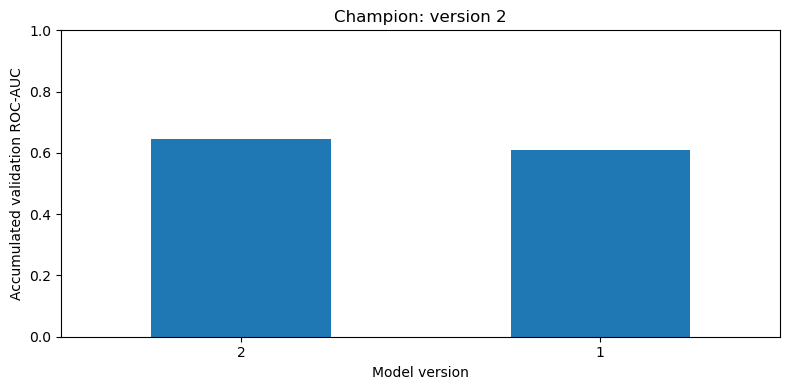

In [29]:
if item and training_done:
    from mlflow.tracking import MlflowClient
    client = MlflowClient()
    path = client.download_artifacts(outcome['comparison_run_id'], 'evaluation/metrics.csv')
    comparison = pd.read_csv(path, dtype={'version': str})
    columns = ['version', 'algorithm', 'cohort', 'created_batch', 'training_batches',
               'split', 'evaluation_batch', 'training_rows_seen', 'n', 'positive',
               'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc',
               'tn', 'fp', 'fn', 'tp']
    display(comparison[columns].sort_values(['version', 'split', 'evaluation_batch']))
    aggregate = comparison[(comparison['split'] == 'validation') & (comparison['evaluation_batch'] == 'all')]
    if not aggregate.empty:
        ax = aggregate.set_index('version')['roc_auc'].plot.bar(figsize=(8, 4), ylim=(0, 1), rot=0)
        ax.set_ylabel('Accumulated validation ROC-AUC'); ax.set_xlabel('Model version')
        ax.set_title('Champion: version ' + str(outcome['champion_after']))
        plt.tight_layout(); plt.show()

In [30]:
if item and training_done:
    finish_batch(item)
    print('Completed:', item['batch_id'])
elif item:
    print('Training has not completed; batch remains pending.')
else:
    print('Nothing to process.')

Completed: batch_0001


The notebook verifies the shared Python functions in Jupyter. Airflow still needs its own compatible dependencies and configuration; see the project README before triggering the DAG. Use notebook 06 to inspect the database after this walkthrough.